In [1]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("itsmonir31/hydroponics-datasets")

print("Path to dataset files:", path)

c:\Users\GwynethCataylo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 2.20M/2.20M [00:00<00:00, 2.36MB/s]

Extracting files...


Path to dataset files: C:\Users\GwynethCataylo\.cache\kagglehub\datasets\itsmonir31\hydroponics-datasets\versions\1


In [25]:
# import necessary libraries and set the path to the dataset
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The folder where the dataset was downloaded
DATASET_DIR = r"C:\Users\GwynethCataylo\Downloads\MODESIM\FINALS\kagglehub\datasets\itsmonir31\hydroponics-datasets\versions\1"

# Combine the folder and the CSV filename
RAW_PATH = os.path.join(DATASET_DIR, "IoTData --Raw--.csv")

In [26]:
# Load the raw CSV file into a DataFrame and display basic information
df = pd.read_csv(RAW_PATH)

print("First 5 rows of the dataset:")
print(df.head())
print("\nData types and non-null values: ")
df.info()
print("\nDescriptive statistics: ")
df.describe()

First 5 rows of the dataset:
   id            timestamp   pH    TDS  water_level  DHT_temp  DHT_humidity  \
0   1  2023-11-26 10:57:52  7.0  500.0            0      25.5          60.0   
1   2  2023-11-26 10:58:37  7.0  500.0            0      25.5          60.0   
2   3  2023-11-26 11:01:34  7.0  500.0            3      25.5          60.0   
3   4  2023-12-05 11:30:58  7.0  500.0            3      25.5          60.0   
4   5  2023-12-05 11:33:50  7.0  500.0            3      25.5          60.0   

   water_temp pH_reducer add_water nutrients_adder humidifier ex_fan  
0        20.0         ON       NaN             OFF        OFF     ON  
1        20.0         ON       NaN             OFF        OFF    OFF  
2        20.0         ON       NaN             OFF        OFF    OFF  
3        20.0         ON       NaN             OFF        OFF    OFF  
4        20.0         ON        ON             OFF        OFF    OFF  

Data types and non-null values: 
<class 'pandas.DataFrame'>
RangeInde

,id,pH,TDS,water_level,DHT_temp,DHT_humidity,water_temp
count,50570.000000,50570.000000,50570.000000,50570.000000,50570.000000,50570.000000,50570.000000
mean,25285.500000,6.001514,1154.134377,1.258829,24.316781,71.714188,21.494904
std,14598.445893,0.553016,247.507196,0.479218,1.209319,25.956493,2.174898
min,1.000000,0.270000,-283.910000,0.000000,12.300000,25.000000,0.000000
25%,12643.250000,5.630000,1020.040000,1.000000,23.600000,67.500000,19.770000
50%,25285.500000,5.790000,1234.650000,1.000000,24.400000,71.700000,21.520000
75%,37927.750000,6.680000,1329.067500,2.000000,25.100000,77.500000,23.277500
max,50570.000000,11.570000,2278.350000,3.000000,70.000000,3312.600000,25.000000


In [27]:
# Convert timestamp and drop the 4 rows missing  'add_water' 
df['timestamp'] = pd.to_datetime(df['timestamp'])

print("\nMissing values in add_water before handling: " , df['add_water'].isnull().sum())
df.dropna(subset=['add_water'], inplace=True) # only 4 rows out of 50,000+ -- safe to drop
print("New shape after droppping:", df.shape)


Missing values in add_water before handling:  4
New shape after droppping: (50566, 13)


In [28]:
# Fix physically impossible sensor values (e.g., negative pH, EC, water level, etc.)
print(f"\nNegative TDS values: {(df['TDS'] < 0).sum()}")
df.loc[df['TDS'] < 0, 'TDS'] = 0  # Set negative TDS values to 0

print(f"DHT_humidity > 100: {(df['DHT_humidity'] > 100).sum()}")
df.loc[df['DHT_humidity'] > 100, 'DHT_humidity'] = 100  # Cap humidity at 100%


Negative TDS values: 25
DHT_humidity > 100: 3


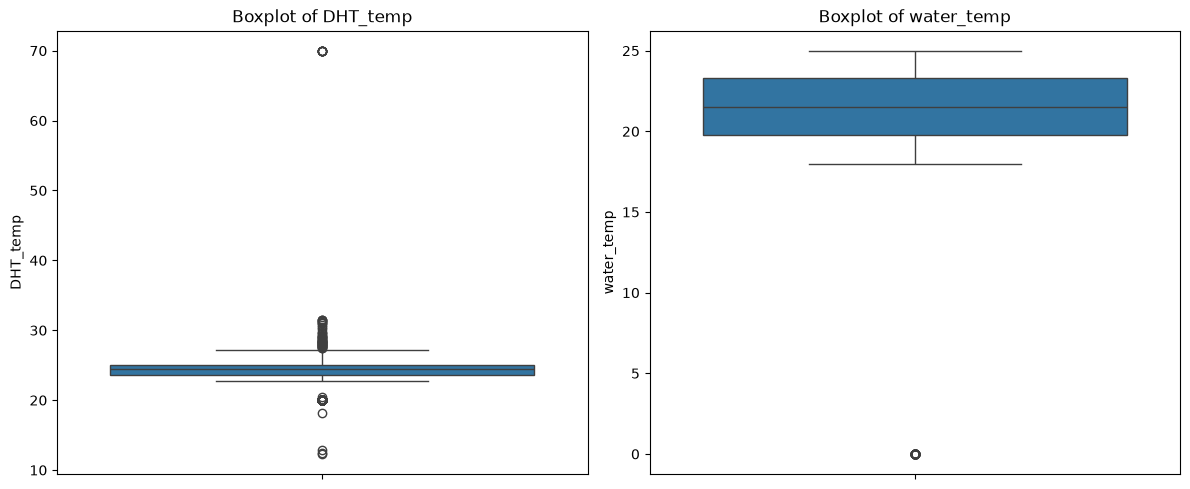

In [ ]:
# Inspect and cap temperature outliers through draw box plots for visualization
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['DHT_temp'])
plt.title('Boxplot of DHT_temp')
plt.subplot(1, 2, 2)
sns.boxplot(y=df['water_temp'])
plt.title('Boxplot of water_temp')
plt.tight_layout()
plt.show()

In [34]:
# Threshold that defines outliers or sensor faults rather than real temperature readings
n_hot = (df["DHT_temp"] > 40).sum()
if n_hot:
    print(f"Capping {n_hot} 'DHT_temp' values above 40°C (sensor-fault threshold).")
    df.loc[df["DHT_temp"] > 40, "DHT_temp"] = 40

n_cold = (df["water_temp"] < 5).sum()
if n_cold:
    print(f"Capping {n_cold} 'water_temp' values below 5°C (sensor-fault threshold).")
    df.loc[df["water_temp"] < 5, "water_temp"] = 5

Capping 8 'DHT_temp' values above 40°C (sensor-fault threshold).
Capping 72 'water_temp' values below 5°C (sensor-fault threshold).


In [36]:
# Standarize actuator columns to ON/OFF (NaN-safe)
categorical_cols = ['pH_reducer', 'add_water', 'nutrients_adder', 'humidifier', 'ex_fan']

for col in categorical_cols:
    print(f"\nUnique values in '{col}' before standardization:", df[col].unique())
    df[col] = df[col].astype(str).str.strip().str.upper()  # Convert to string, strip whitespace, and uppercase
    # Only rows that are NOT NULL and not already 'OFF' will be touch -- nulls stay null
    mask = df[col].notna() & (df[col] != "OFF") & (df[col] != "NAN")
    df.loc[mask, col] = 'ON'
    df.loc[df[col] == 'NAN', col] = pd.NA # Convert 'NAN' strings to actual NaN
    print(f"Unique values in '{col}' after standardization:", df[col].unique())


Unique values in 'pH_reducer' before standardization: <StringArray>
['ON', 'OFF']
Length: 2, dtype: str
Unique values in 'pH_reducer' after standardization: <StringArray>
['ON', 'OFF']
Length: 2, dtype: str

Unique values in 'add_water' before standardization: <StringArray>
['ON', 'OFF']
Length: 2, dtype: str
Unique values in 'add_water' after standardization: <StringArray>
['ON', 'OFF']
Length: 2, dtype: str

Unique values in 'nutrients_adder' before standardization: <StringArray>
['OFF', 'ON']
Length: 2, dtype: str
Unique values in 'nutrients_adder' after standardization: <StringArray>
['OFF', 'ON']
Length: 2, dtype: str

Unique values in 'humidifier' before standardization: <StringArray>
['OFF', 'ON']
Length: 2, dtype: str
Unique values in 'humidifier' after standardization: <StringArray>
['OFF', 'ON']
Length: 2, dtype: str

Unique values in 'ex_fan' before standardization: <StringArray>
['OFF', 'ON']
Length: 2, dtype: str
Unique values in 'ex_fan' after standardization: <StringArr

In [37]:
# Resample onto a uniform 1 minute grid
df = df.sort_values('timestamp').set_index('timestamp')

numeric_cols = ["pH", "TDS", "water_level", "DHT_temp", "DHT_humidity", "water_temp"]
df_numeric = df[numeric_cols].resample("1min").mean()  # Resample numeric columns with mean, average if >1 reading in a minute
df_numric = df_numeric.interpolate(method='time', limit=30)  # Interpolate missing values in numeric columns, fill the gaps up to 30 mins only

df_actuators = df[categorical_cols].resample("1min").ffill()   # Resample actuator columns with forward fill, keep the last known state for each minute

df_resampled = df_numeric.join(df_actuators)
print(f"\nBefore resampling: {len(df)} irregular rows")
print(f"After resampling to 1-minute grid: {len(df_resampled)} rows" 
      f"({df_resampled.notna().all(axis=1).sum()} complete)")
      


Before resampling: 50566 irregular rows
After resampling to 1-minute grid: 30844 rows(6702 complete)


In [40]:
# Final cleaned data set
print("\nFinal cleaned & resampled dataset:")
print(df_resampled.head())
print(df_resampled.describe())
 
df_resampled.to_csv(CLEAN_PATH)
print(f"\nSaved cleaned dataset to {CLEAN_PATH}")


Final cleaned & resampled dataset:
                      pH    TDS  water_level  DHT_temp  DHT_humidity  \
timestamp                                                              
2023-12-05 11:33:00  7.0  500.0          3.0      25.5          60.0   
2023-12-05 11:34:00  7.0  500.0          3.0      25.5          60.0   
2023-12-05 11:35:00  NaN    NaN          NaN       NaN           NaN   
2023-12-05 11:36:00  NaN    NaN          NaN       NaN           NaN   
2023-12-05 11:37:00  NaN    NaN          NaN       NaN           NaN   

                     water_temp pH_reducer add_water nutrients_adder  \
timestamp                                                              
2023-12-05 11:33:00        20.0        NaN       NaN             NaN   
2023-12-05 11:34:00        20.0         ON        ON             OFF   
2023-12-05 11:35:00         NaN         ON        ON             OFF   
2023-12-05 11:36:00         NaN         ON        ON             OFF   
2023-12-05 11:37:00        